# Image Analysis – Masks, Morphology & Evaluation

## Project Overview

This notebook focuses on analyzing the Field-PDD dataset, inspecting ground-truth masks, checking dataset consistency, analyzing connected components, and experimenting with morphological operations.

## Objectives

- Inspect the dataset structure and distribution.
- Verify image and mask integrity.
- Analyze ground-truth mask pixel values.
- Examine the consistency between black images and label masks.
- Analyze connected components.
- Apply morphological operations and compare their effects.
- Prepare evaluation metrics for segmentation analysis.

## 1. Import Libraries

This section imports the Python libraries required for dataset handling, image processing, numerical operations, and visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

from PIL import Image
from collections import Counter, defaultdict

## 2. Clone Project Repository

This section clones the project repository and checks out the assigned branch containing the mask morphology and evaluation work.

In [ ]:
!git clone --branch feat/masks-morphology-eval-prep https://github.com/lorianca/image-project-.git

Cloning into 'image-project-'...
remote: Enumerating objects: 96, done.
remote: Counting objects: 100% (96/96), done.
remote: Compressing objects: 100% (80/80), done.
remote: Total 96 (delta 32), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (96/96), 5.53 MiB | 9.40 MiB/s, done.
Resolving deltas: 100% (32/32), done.


## Repository Information

This section verifies the current project directory and the assigned Git branch.

In [ ]:
%cd /content/image-project-

!git branch --show-current

!ls -R

/content/image-project-
feat/masks-morphology-eval-prep
.:
README.md  requirements.txt  split.csv	src

./src:
evaluate.py


## Dataset Loading

This section loads the dataset manifest, which contains the image paths, black image paths, label mask paths, disease classes, and dataset splits.

In [ ]:
df = pd.read_csv('/content/image-project-/split.csv')

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

Shape: (240, 6)

Columns:
['class', 'name', 'image', 'black', 'label', 'split']

First 10 rows:


,class,name,image,black,label,split
0,soybean_bacterial_blight,Soybean_0090,soybean_bacterial_blight/Soybean_0090.jpg,soybean_bacterial_blight/Soybean_0090_black.png,soybean_bacterial_blight/Soybean_0090_label.png,train
1,wheat_stripe_rust,Wheat_C230514_0082,wheat_stripe_rust/Wheat_C230514_0082.jpg,wheat_stripe_rust/Wheat_C230514_0082_black.png,wheat_stripe_rust/Wheat_C230514_0082_label.png,train
2,soybean_bacterial_blight,Soybean_0166,soybean_bacterial_blight/Soybean_0166.jpg,soybean_bacterial_blight/Soybean_0166_black.png,soybean_bacterial_blight/Soybean_0166_label.png,train
3,cedar_apple_rust,Apple_0369,cedar_apple_rust/Apple_0369.jpg,cedar_apple_rust/Apple_0369_black.png,cedar_apple_rust/Apple_0369_label.png,train
4,cedar_apple_rust,Apple_0241,cedar_apple_rust/Apple_0241.jpg,cedar_apple_rust/Apple_0241_black.png,cedar_apple_rust/Apple_0241_label.png,train
5,wheat_stripe_rust,Wheat_C230514_0089,wheat_stripe_rust/Wheat_C230514_0089.jpg,wheat_stripe_rust/Wheat_C230514_0089_black.png,wheat_stripe_rust/Wheat_C230514_0089_label.png,train
6,wheat_stripe_rust,Wheat_C230514_0092,wheat_stripe_rust/Wheat_C230514_0092.jpg,wheat_stripe_rust/Wheat_C230514_0092_black.png,wheat_stripe_rust/Wheat_C230514_0092_label.png,train
7,soybean_bacterial_blight,Soybean_0061,soybean_bacterial_blight/Soybean_0061.jpg,soybean_bacterial_blight/Soybean_0061_black.png,soybean_bacterial_blight/Soybean_0061_label.png,train
8,wheat_stripe_rust,Wheat_C230514_0084,wheat_stripe_rust/Wheat_C230514_0084.jpg,wheat_stripe_rust/Wheat_C230514_0084_black.png,wheat_stripe_rust/Wheat_C230514_0084_label.png,train
9,soybean_bacterial_blight,Soybean_0179,soybean_bacterial_blight/Soybean_0179.jpg,soybean_bacterial_blight/Soybean_0179_black.png,soybean_bacterial_blight/Soybean_0179_label.png,train


## Dataset Overview

This section examines the dataset distribution across disease classes and data splits. It also checks for duplicated sample names.

In [ ]:
print("Images in each split:")
print(df['split'].value_counts())

print("\nImages in each class:")
print(df['class'].value_counts())

print("\nClass distribution in each split:")
display(pd.crosstab(df['class'], df['split']))

print("\nDuplicate sample names:")
print(df['name'].duplicated().sum())

Images in each split:
split
train    168
val       36
test      36
Name: count, dtype: int64

Images in each class:
class
soybean_bacterial_blight    80
wheat_stripe_rust           80
cedar_apple_rust            80
Name: count, dtype: int64

Class distribution in each split:


split,test,train,val
class,,,
cedar_apple_rust,12,56,12
soybean_bacterial_blight,12,56,12
wheat_stripe_rust,12,56,12



Duplicate sample names:
0


### Dataset Overview – Results

The dataset contains 240 samples distributed across three classes.

- Training set: 168 images (70%).
- Validation set: 36 images (15%).
- Test set: 36 images (15%).

Each class contains 80 images, with 56 training samples, 12 validation samples, and 12 testing samples.

No duplicate sample names were found.

**Conclusion:** The dataset has a balanced class distribution and an equal split ratio across all three classes.

## Dataset Download

This section downloads the Field-PDD dataset using KaggleHub and retrieves the dataset directory.

In [56]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("alexzcheny/testdataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'testdataset' dataset.
Path to dataset files: /kaggle/input/testdataset


## Dataset Directory Structure

This section identifies the dataset location and displays its folder structure.

In [57]:
DATASET_PATH = path
DATASET_DIR = os.path.join(DATASET_PATH, "Dataset")

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

testdataset/
  Dataset/
    soybean_bacterial_blight/
      Soybean_0243_label.png
      Soybean_0060_label.png
      Soybean_0027_black.png
      Soybean_0250.jpg
      Soybean_0061_black.png
    wheat_stripe_rust/
      Wheat_C230514_0023.jpg
      Wheat_C230514_0062.jpg
      Wheat_C230514_0012.jpg
      Wheat_C230514_0098_label.png
      Wheat_C230514_0032_label.png
    cedar_apple_rust/
      Apple_0064_label.png
      Apple_0208.jpg
      Apple_0322_label.png
      Apple_0218_black.png
      Apple_0323.jpg
  OriginalData/
    soybean_bacterial_blight/
      Soybean_0250.jpg
      Soybean_0027.jpg
      Soybean_0031.jpg
      Soybean_0071.jpg
      Soybean_0026.jpg
    wheat_stripe_rust/
      Wheat_C230514_0023.jpg
      Wheat_C230514_0062.jpg
      Wheat_C230514_0012.jpg
      Wheat_C230514_0013.jpg
      Wheat_C230514_0073.jpg
    cedar_apple_rust/
      Apple_0208.jpg
      Apple_0323.jpg
      Apple_0333.jpg
      Apple_0334.jpg
      Apple_0277.jpg


## Dataset Integrity – File Existence

This section verifies that all original images, black images, and label masks listed in the manifest exist in the dataset directory.

In [ ]:
DATASET_DIR = os.path.join(DATASET_PATH, "Dataset")

missing = []

for _, row in df.iterrows():
    for column in ["image", "black", "label"]:
        file_path = os.path.join(DATASET_DIR, row[column])

        if not os.path.isfile(file_path):
            missing.append((row["name"], column, file_path))

print("Total samples:", len(df))
print("Expected files:", len(df) * 3)
print("Missing files:", len(missing))

if missing:
    print("\nMissing files details:")
    for item in missing[:20]:
        print(item)
else:
    print("\nAll image and mask files exist!")

Total samples: 240
Expected files: 720
Missing files: 0

All image and mask files exist!


## Image and Mask Dimensions

This section checks whether the original image, black image, and label mask have matching dimensions for every sample.

In [ ]:
dimension_errors = []

for _, row in df.iterrows():
    image_path = os.path.join(DATASET_DIR, row["image"])
    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(black_path) as img:
        black_size = img.size

    with Image.open(label_path) as img:
        label_size = img.size

    if image_size != black_size or image_size != label_size:
        dimension_errors.append({
            "name": row["name"],
            "image": image_size,
            "black": black_size,
            "label": label_size
        })

print("Total checked:", len(df))
print("Dimension mismatches:", len(dimension_errors))

if dimension_errors:
    for error in dimension_errors[:10]:
        print(error)
else:
    print("All image, black, and label dimensions match!")

Total checked: 240
Dimension mismatches: 0
All image, black, and label dimensions match!


### Image and Mask Dimensions Validation

All 240 samples were checked to verify that each original image, black mask, and label mask has matching dimensions.

- Total samples checked: 240
- Dimension mismatches: 0
- Result: All image and mask dimensions match.

**Conclusion:** The dataset passed the image and mask dimension consistency check.

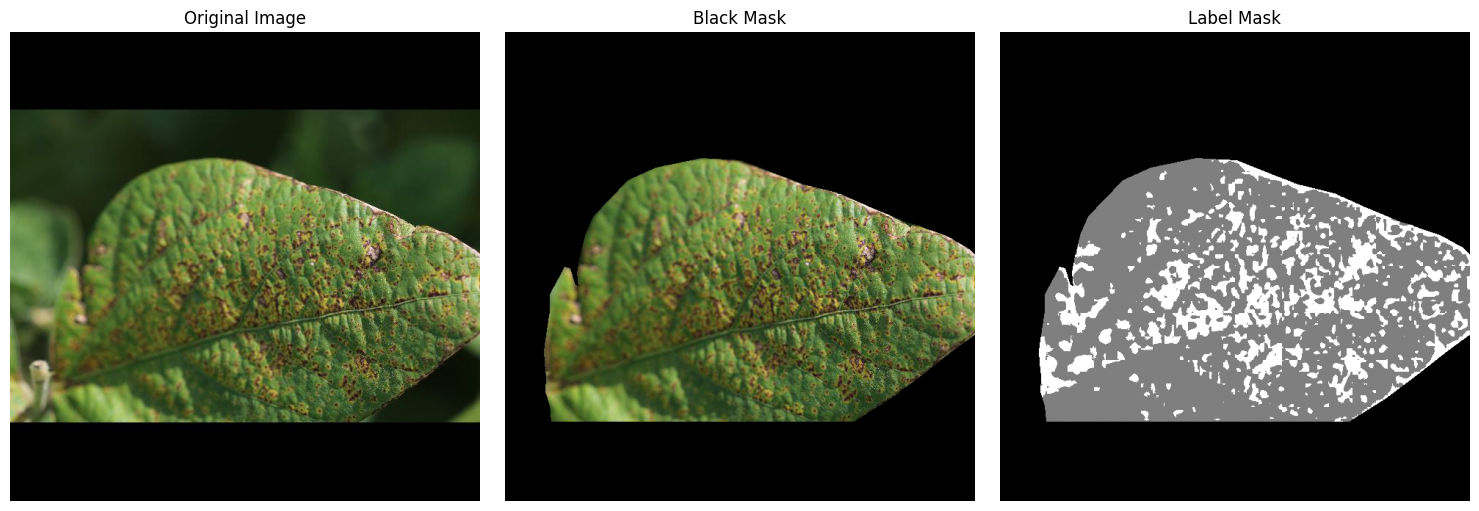

Sample: Soybean_0090
Image mode: RGB
Black mode: RGB
Label mode: L
Black unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Label unique values: [  0 127 255]


In [ ]:
sample = df.iloc[0]

image_path = os.path.join(DATASET_DIR, sample["image"])
black_path = os.path.join(DATASET_DIR, sample["black"])
label_path = os.path.join(DATASET_DIR, sample["label"])

image = Image.open(image_path)
black = Image.open(black_path)
label = Image.open(label_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(black, cmap="gray")
axes[1].set_title("Black Mask")

axes[2].imshow(label, cmap="gray")
axes[2].set_title("Label Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sample:", sample["name"])
print("Image mode:", image.mode)
print("Black mode:", black.mode)
print("Label mode:", label.mode)

print("Black unique values:", np.unique(np.array(black))[:20])
print("Label unique values:", np.unique(np.array(label))[:20])

### Label Mask Visualization

This section visualizes the different pixel values in the label mask using different colors.

- 0: Black
- 127: Yellow
- 255: Red

The visualization helps distinguish the different regions in the label mask.

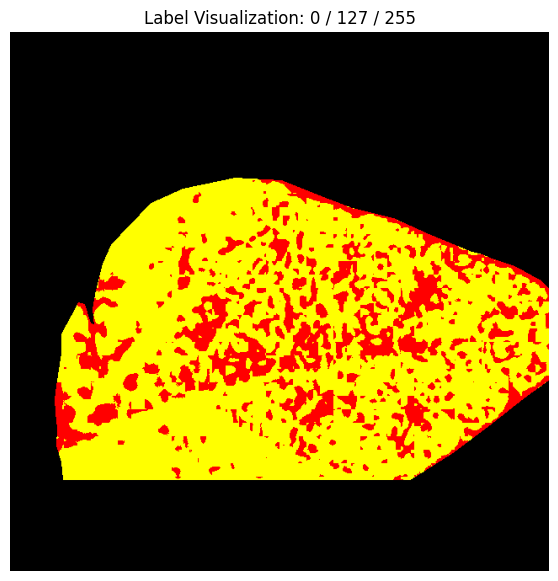

In [ ]:
label_array = np.array(label)

colored_label = np.zeros(
    (label_array.shape[0], label_array.shape[1], 3),
    dtype=np.uint8
)

colored_label[label_array == 0] = [0, 0, 0]
colored_label[label_array == 127] = [255, 255, 0]
colored_label[label_array == 255] = [255, 0, 0]

plt.figure(figsize=(7, 7))
plt.imshow(colored_label)
plt.title("Label Visualization: 0 / 127 / 255")
plt.axis("off")
plt.show()

### Label Mask Integrity Check

This section checks all label masks to identify their unique pixel values and verify that each mask is a grayscale image.

The check also records any files that cannot be read correctly.

In [ ]:
label_values = Counter()
label_errors = []

for _, row in df.iterrows():
    path = os.path.join(DATASET_DIR, row["label"])

    try:
        mask = np.array(Image.open(path))

        if mask.ndim != 2:
            label_errors.append((row["name"], "Not grayscale"))
            continue

        values = np.unique(mask)
        label_values.update(values.tolist())

    except Exception as e:
        label_errors.append((row["name"], str(e)))

print("Pixel values found across all labels:")
print(label_values)

print("\nNumber of labels checked:", len(df))
print("Label errors:", len(label_errors))

if label_errors:
    print(label_errors[:10])

Pixel values found across all labels:
Counter({0: 240, 127: 240, 255: 240})

Number of labels checked: 240
Label errors: 0


### Label Pixel Distribution Analysis

This section calculates the total number of pixels for each unique value across all 240 label masks.

It also calculates the percentage of each pixel value in the complete dataset to understand the distribution of the mask regions.

In [ ]:
pixel_counts = defaultdict(int)

for _, row in df.iterrows():
    path = os.path.join(DATASET_DIR, row["label"])
    mask = np.array(Image.open(path))

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

total = sum(pixel_counts.values())

print("Total pixels:", total)

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    percentage = count / total * 100

    print(
        f"Value {value}: {count:,} pixels "
        f"({percentage:.2f}%)"
    )

Total pixels: 98304000
Value 0: 77,110,575 pixels (78.44%)
Value 127: 17,597,089 pixels (17.90%)
Value 255: 3,596,336 pixels (3.66%)


### Black Image RGB Analysis

This section examines the RGB channels of a sample black image.

It checks the image dimensions, data type, number of unique values in each color channel, and whether all three channels contain identical values.

In [ ]:
row = df.iloc[0]

black_path = os.path.join(DATASET_DIR, row["black"])

black_array = np.array(
    Image.open(black_path).convert("RGB")
)

print("Shape:", black_array.shape)
print("Data type:", black_array.dtype)

print(
    "Red channel unique values:",
    len(np.unique(black_array[:, :, 0]))
)

print(
    "Green channel unique values:",
    len(np.unique(black_array[:, :, 1]))
)

print(
    "Blue channel unique values:",
    len(np.unique(black_array[:, :, 2]))
)

print(
    "Are all RGB channels identical?",
    np.array_equal(black_array[:, :, 0], black_array[:, :, 1])
    and np.array_equal(black_array[:, :, 1], black_array[:, :, 2])
)

Shape: (640, 640, 3)
Data type: uint8
Red channel unique values: 250
Green channel unique values: 251
Blue channel unique values: 242
Are all RGB channels identical? False


### Most Common RGB Colors

This section identifies the ten most frequent RGB colors in the selected black image.

The results help describe the color distribution within the image.

In [ ]:
colors, counts = np.unique(
    black_array.reshape(-1, 3),
    axis=0,
    return_counts=True
)

top_indices = np.argsort(counts)[-10:][::-1]

print("Most common RGB colors:")

for i in top_indices:
    print(colors[i], counts[i])

Most common RGB colors:
[0 0 0] 242599
[52 78 33] 46
[44 70 33] 41
[42 70 32] 39
[50 75 35] 39
[51 77 32] 38
[50 76 31] 38
[53 78 36] 38
[41 67 32] 36
[51 76 34] 34


### Black Image and Label Mask Consistency Check

This section compares black pixels in the black image with pixel values in the corresponding label mask.

It identifies whether black pixels correspond to label value 0 and checks for any mismatches with label value 255.

In [ ]:
row = df.iloc[0]

black_path = os.path.join(DATASET_DIR, row["black"])
label_path = os.path.join(DATASET_DIR, row["label"])

black_array = np.array(
    Image.open(black_path).convert("RGB")
)

label_array = np.array(
    Image.open(label_path)
)

black_pixels = np.all(black_array == 0, axis=2)

for value in [0, 127, 255]:
    total = np.sum(label_array == value)

    black_count = np.sum(
        (label_array == value) & black_pixels
    )

    non_black_count = total - black_count

    print(f"\nLabel value: {value}")
    print("Total pixels:", total)
    print("Black pixels:", black_count)
    print("Non-black pixels:", non_black_count)


Label value: 0
Total pixels: 242599
Black pixels: 242599
Non-black pixels: 0

Label value: 127
Total pixels: 125544
Black pixels: 0
Non-black pixels: 125544

Label value: 255
Total pixels: 41457
Black pixels: 0
Non-black pixels: 41457


### Dataset-wide Black and Label Consistency Analysis

This section performs the same black pixel consistency check across all 240 samples.

It counts black pixels associated with each label value and records images containing black pixels where the label value is 255.

In [ ]:
consistency_counts = {
    0: {"black": 0, "non_black": 0},
    127: {"black": 0, "non_black": 0},
    255: {"black": 0, "non_black": 0}
}

exception_images = []

for _, row in df.iterrows():

    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    black_array = np.array(
        Image.open(black_path).convert("RGB")
    )

    label_array = np.array(
        Image.open(label_path)
    )

    black_pixels = np.all(black_array == 0, axis=2)

    exception_count = np.sum(
        (label_array == 255) & black_pixels
    )

    if exception_count > 0:
        exception_images.append({
            "name": row["name"],
            "split": row["split"],
            "exception_pixels": int(exception_count)
        })

    for value in [0, 127, 255]:

        total = np.sum(label_array == value)

        black_count = np.sum(
            (label_array == value) & black_pixels
        )

        non_black_count = total - black_count

        consistency_counts[value]["black"] += int(black_count)
        consistency_counts[value]["non_black"] += int(non_black_count)

print("Dataset-wide consistency results:")

for value in [0, 127, 255]:
    print(f"\nLabel value: {value}")
    print("Black pixels:", consistency_counts[value]["black"])
    print("Non-black pixels:", consistency_counts[value]["non_black"])

print("\nImages with exceptions:", len(exception_images))

Dataset-wide consistency results:

Label value: 0
Black pixels: 77110575
Non-black pixels: 0

Label value: 127
Black pixels: 0
Non-black pixels: 17597089

Label value: 255
Black pixels: 125
Non-black pixels: 3596211

Images with exceptions: 17


### Black and Label Mask Exceptions Report

This section lists samples containing pixels where the black image is black but the corresponding label pixel has value 255.

These cases are recorded for further visual inspection and should not automatically be considered segmentation errors.

In [61]:
exceptions_df = pd.DataFrame(exception_images)

display(
    exceptions_df.sort_values(
        by="exception_pixels",
        ascending=False
    )
)

if not exceptions_df.empty:

    print(
        "Total exception pixels:",
        exceptions_df["exception_pixels"].sum()
    )

    print("\nExceptions by split:")
    print(exceptions_df["split"].value_counts())

else:
    print("No exceptions were detected.")


,name,split,exception_pixels
10,Apple_0301,train,59
13,Apple_0098,train,25
1,Apple_0323,train,11
11,Soybean_0026,train,5
5,Apple_0058,train,5
0,Soybean_0166,train,3
4,Soybean_0054,train,2
3,Soybean_0210,train,2
2,Apple_0092,train,2
12,Apple_0333,train,2


Total exception pixels: 125

Exceptions by split:
split
train    14
val       2
test      1
Name: count, dtype: int64


### Visual Inspection of Exception Samples

This section visually examines a sample containing black pixels where the corresponding label value is 255.

The original image, black image, label mask, and exception mask are displayed together to inspect the detected mismatch.

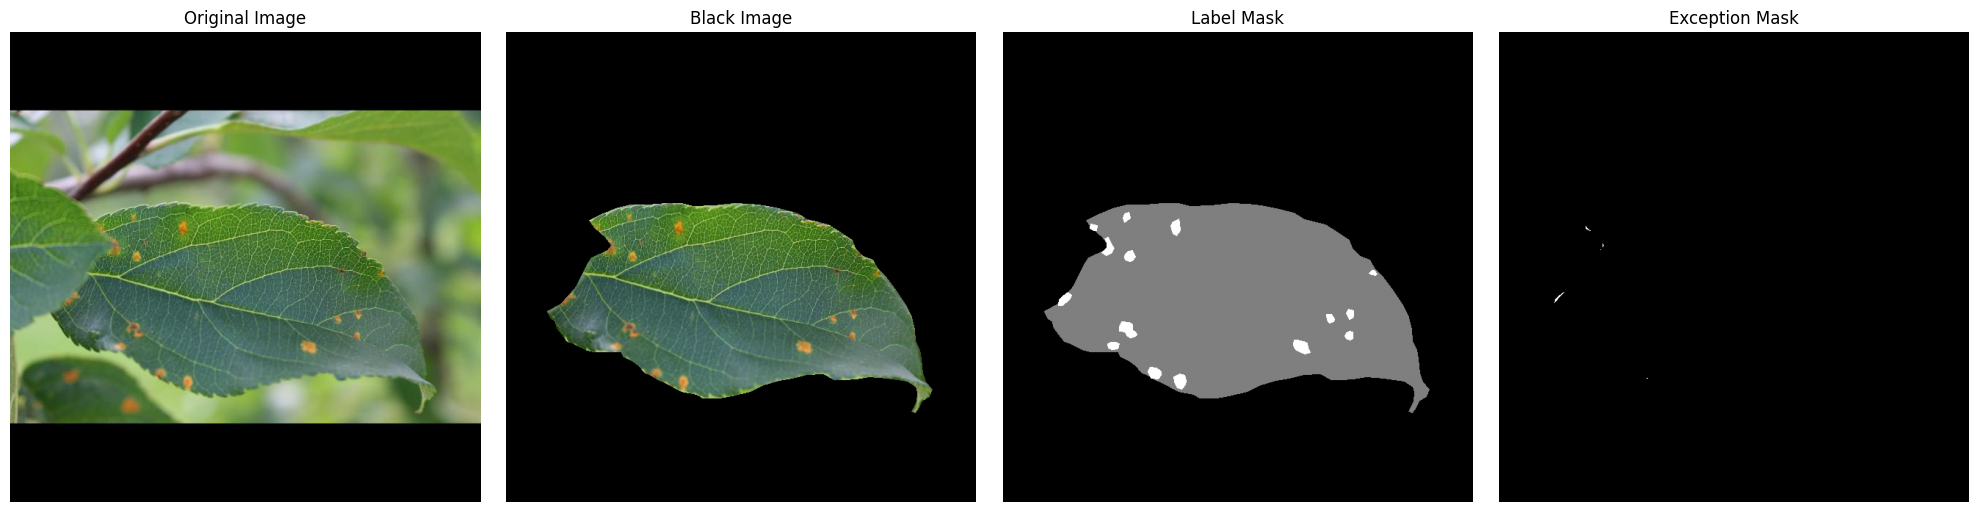

Sample: Apple_0301
Exception pixels: 59


In [ ]:
exception_name = "Apple_0301"

row = df[df["name"] == exception_name].iloc[0]

image_path = os.path.join(DATASET_DIR, row["image"])
black_path = os.path.join(DATASET_DIR, row["black"])
label_path = os.path.join(DATASET_DIR, row["label"])

original = np.array(Image.open(image_path).convert("RGB"))
black_array = np.array(Image.open(black_path).convert("RGB"))
label_array = np.array(Image.open(label_path))

black_pixels = np.all(black_array == 0, axis=2)

exception_mask = (label_array == 255) & black_pixels

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(black_array)
axes[1].set_title("Black Image")

axes[2].imshow(label_array, cmap="gray")
axes[2].set_title("Label Mask")

axes[3].imshow(exception_mask, cmap="gray")
axes[3].set_title("Exception Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sample:", exception_name)
print("Exception pixels:", np.sum(exception_mask))

### Exception Overlay Visualization

This section overlays the detected exception pixels on the original image using red markers.

This visualization makes the locations of the mismatched pixels easier to identify.

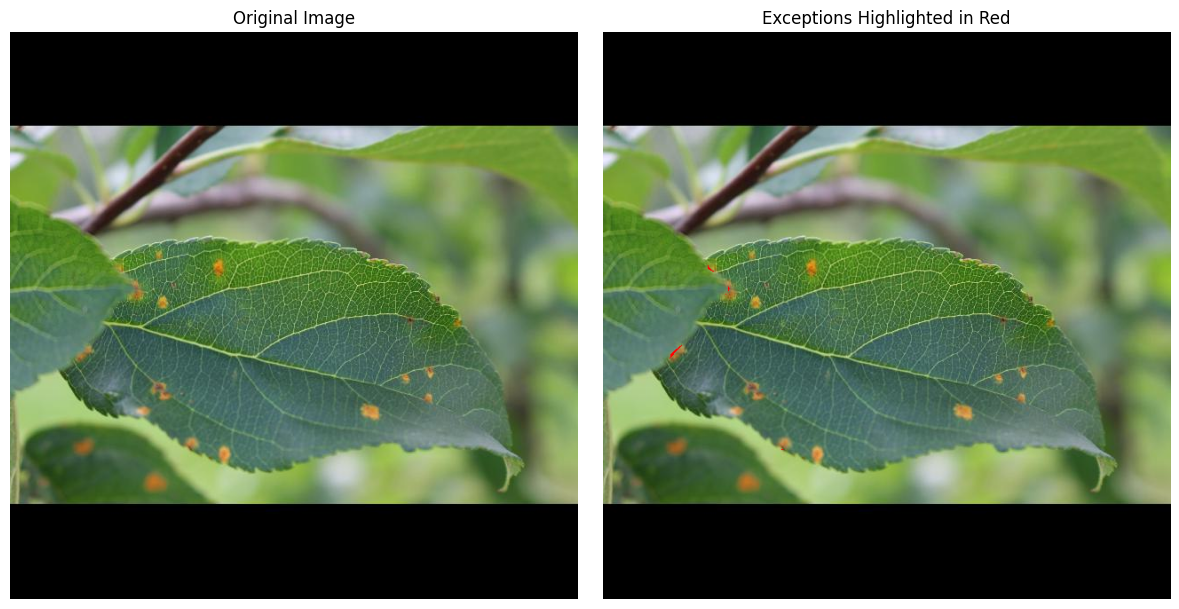

In [ ]:
overlay = original.copy()

overlay[exception_mask] = [255, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(overlay)
axes[1].set_title("Exceptions Highlighted in Red")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### All Exception Samples Visualization

This section displays all samples containing detected black and label mismatches.

Red overlays indicate the locations of pixels where the black image is black while the label value is 255.

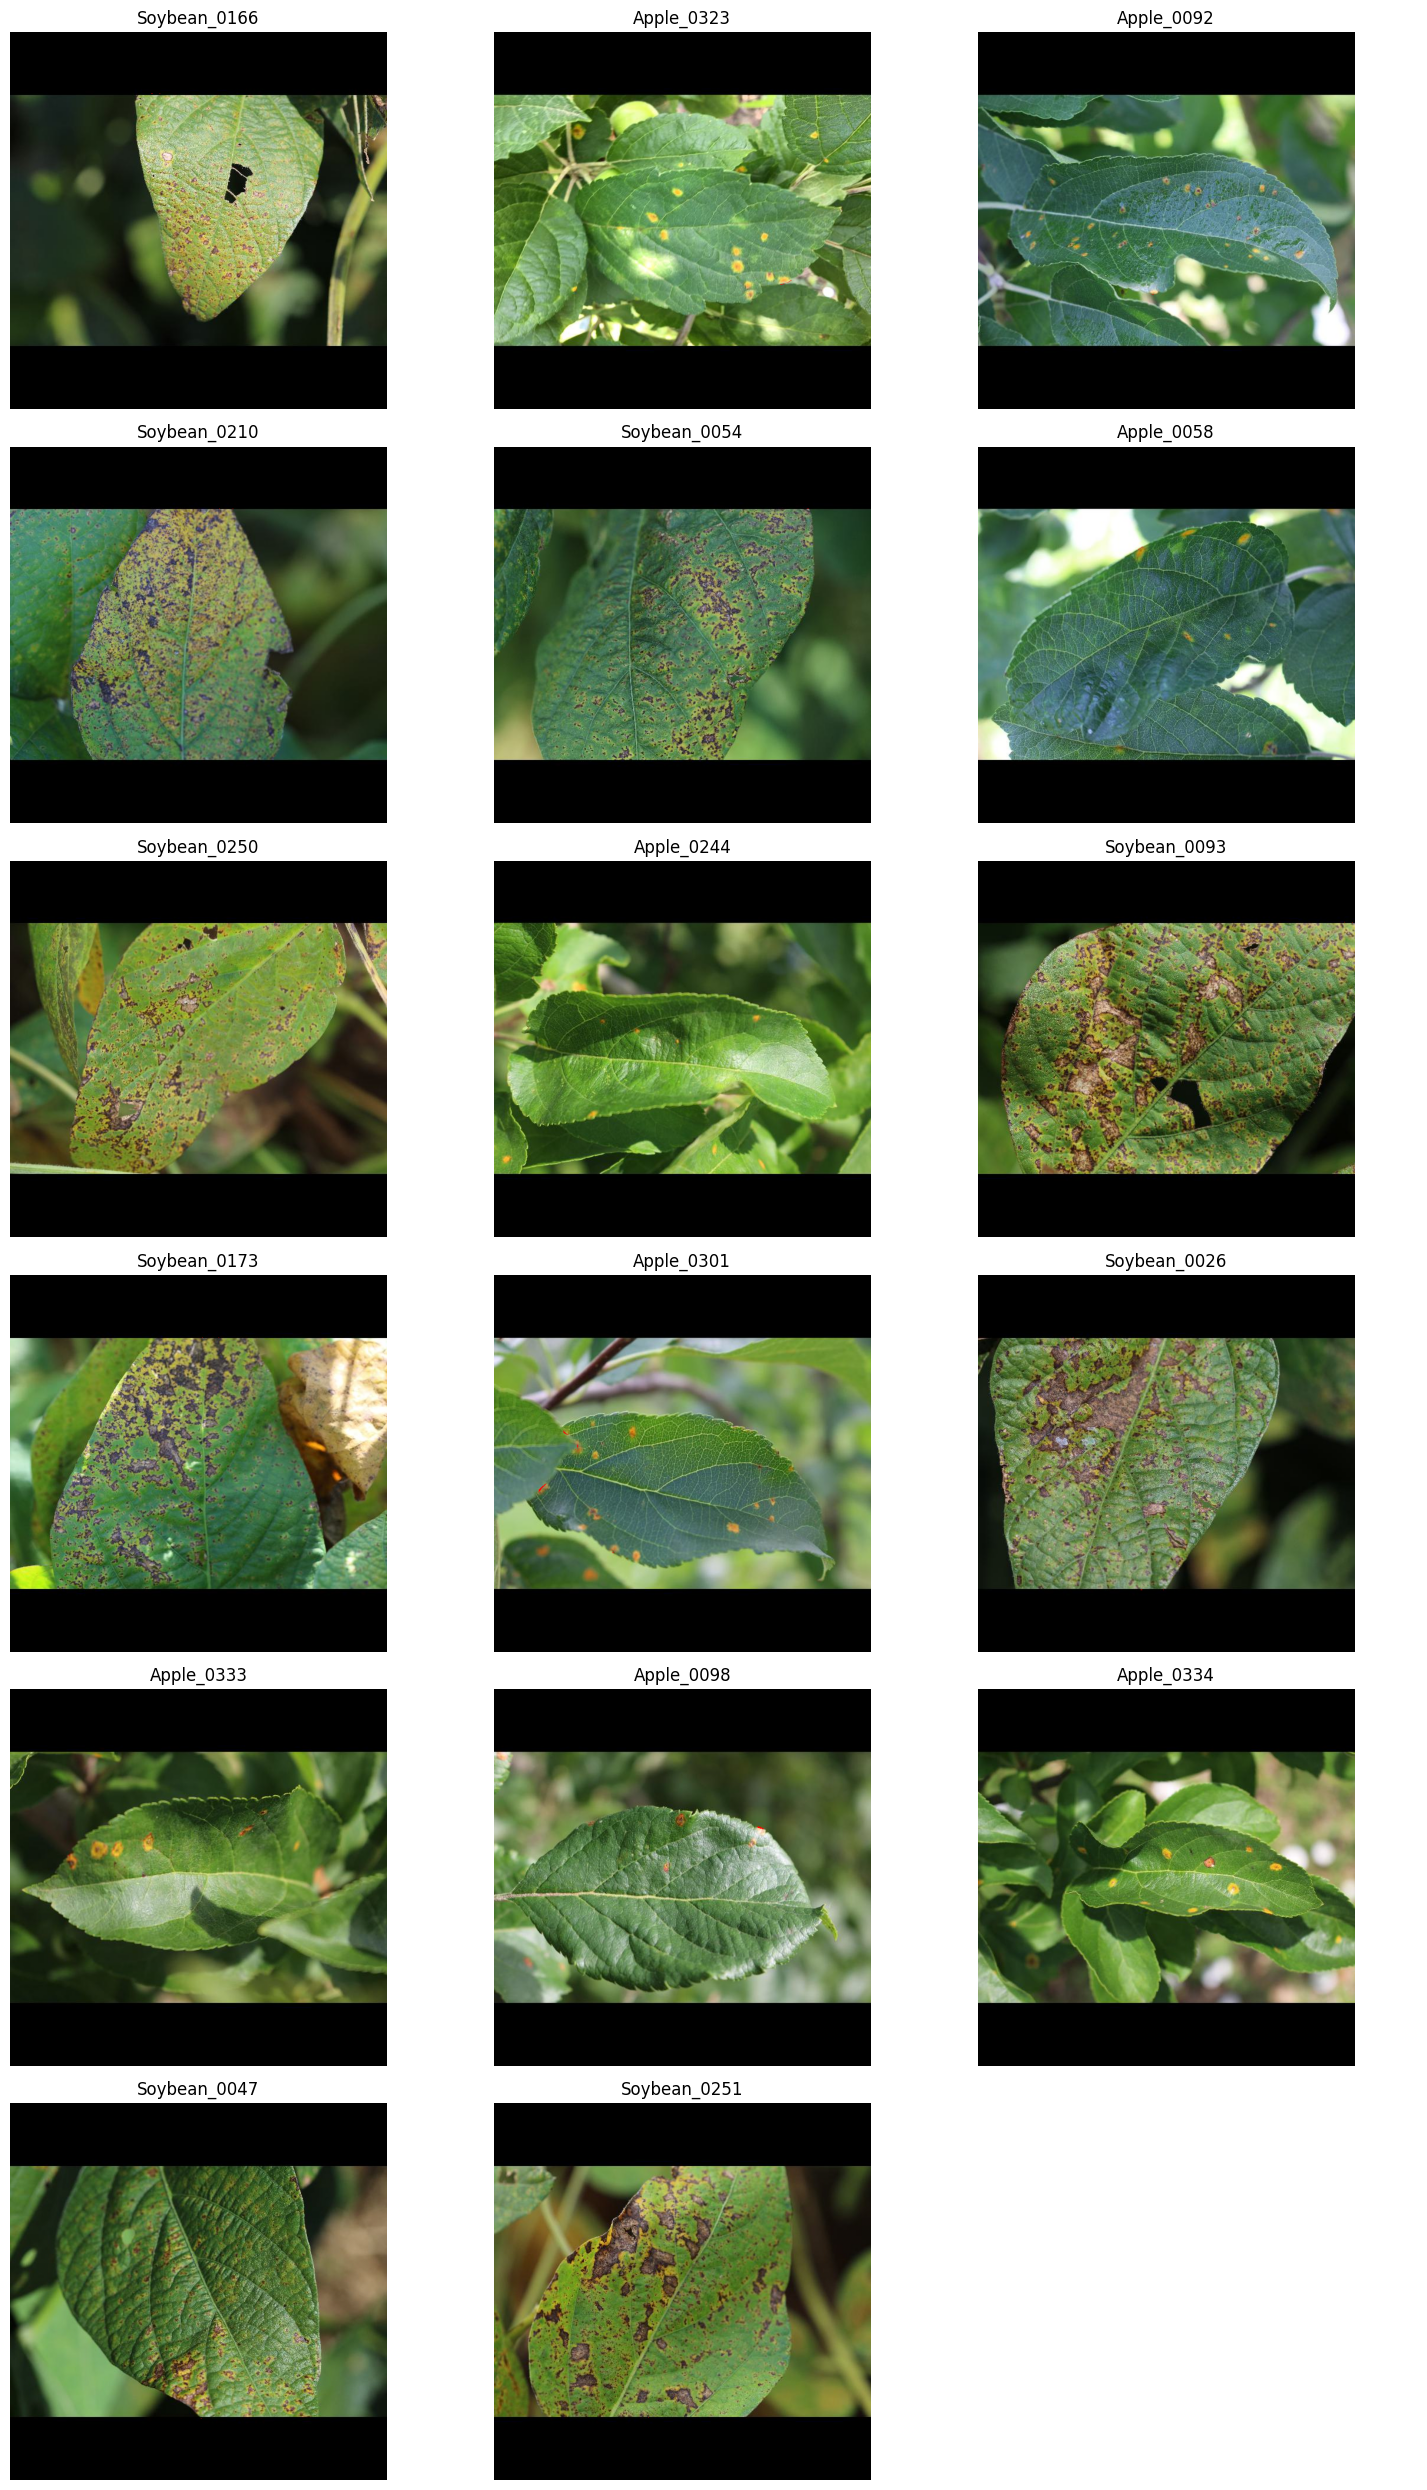

In [ ]:
exception_names = exceptions_df["name"].tolist()

fig, axes = plt.subplots(6, 3, figsize=(15, 25))

for ax, name in zip(axes.flat, exception_names):

    row = df[df["name"] == name].iloc[0]

    image_path = os.path.join(DATASET_DIR, row["image"])
    black_path = os.path.join(DATASET_DIR, row["black"])
    label_path = os.path.join(DATASET_DIR, row["label"])

    original = np.array(
        Image.open(image_path).convert("RGB")
    )

    black_array = np.array(
        Image.open(black_path).convert("RGB")
    )

    label_array = np.array(
        Image.open(label_path)
    )

    black_pixels = np.all(black_array == 0, axis=2)

    exception_mask = (label_array == 255) & black_pixels

    overlay = original.copy()
    overlay[exception_mask] = [255, 0, 0]

    ax.imshow(overlay)
    ax.set_title(name)
    ax.axis("off")

for ax in axes.flat[len(exception_names):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Connected Components Analysis

Connected component analysis identifies separate connected regions in a binary mask.

In this section, pixels with label value 255 are converted into a binary mask. The connected regions are then detected using OpenCV with 8-connectivity.

In [ ]:
row = df.iloc[0]

label_path = os.path.join(DATASET_DIR, row["label"])

mask = np.array(Image.open(label_path))

binary_mask = (mask == 255).astype(np.uint8)

num_labels, components, stats, centroids = cv2.connectedComponentsWithStats(
    binary_mask,
    connectivity=8
)

areas = stats[1:, cv2.CC_STAT_AREA]

print("Sample:", row["name"])
print("Number of components:", len(areas))
print("Largest component area:", areas.max() if len(areas) else 0)
print("Smallest component area:", areas.min() if len(areas) else 0)
print("Average component area:", areas.mean() if len(areas) else 0)

Sample: Soybean_0090
Number of components: 288
Largest component area: 3238
Smallest component area: 1
Average component area: 143.94791666666666


### Dataset-wide Connected Components Analysis

This section applies connected component analysis to all 240 label masks.

For each sample, it records the number of connected components, the largest component area, the smallest component area, and the average component area.

In [ ]:
results = []

for _, row in df.iterrows():

    label_path = os.path.join(DATASET_DIR, row["label"])

    mask = np.array(Image.open(label_path))

    binary_mask = (mask == 255).astype(np.uint8)

    num_labels, components, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    areas = stats[1:, cv2.CC_STAT_AREA]

    results.append({
        "name": row["name"],
        "class": row["class"],
        "split": row["split"],
        "num_components": len(areas),
        "largest_area": areas.max() if len(areas) else 0,
        "smallest_area": areas.min() if len(areas) else 0,
        "average_area": areas.mean() if len(areas) else 0
    })

morphology_df = pd.DataFrame(results)

display(morphology_df.head(10))

,name,class,split,num_components,largest_area,smallest_area,average_area
0,Soybean_0090,soybean_bacterial_blight,train,288,3238,1,143.947917
1,Wheat_C230514_0082,wheat_stripe_rust,train,6,1277,17,317.333333
2,Soybean_0166,soybean_bacterial_blight,train,349,2517,1,52.154728
3,Apple_0369,cedar_apple_rust,train,8,303,79,168.375000
4,Apple_0241,cedar_apple_rust,train,7,991,71,328.000000
5,Wheat_C230514_0089,wheat_stripe_rust,train,24,12900,17,698.125000
6,Wheat_C230514_0092,wheat_stripe_rust,train,11,29273,17,2717.727273
7,Soybean_0061,soybean_bacterial_blight,train,259,4658,1,48.447876
8,Wheat_C230514_0084,wheat_stripe_rust,train,8,15054,17,2067.500000
9,Soybean_0179,soybean_bacterial_blight,train,333,3590,1,65.426426


### Connected Components Statistical Summary

This section summarizes the connected component measurements across the complete dataset.

It provides descriptive statistics for the number of components and their areas.

In [ ]:
print("Connected Components Summary:")

display(
    morphology_df[
        ["num_components", "largest_area", "smallest_area", "average_area"]
    ].describe()
)

Connected Components Summary:


,num_components,largest_area,smallest_area,average_area
count,240.000000,240.000000,240.000000,240.000000
mean,92.858333,6547.208333,129.525000,478.389662
std,125.973551,9229.414773,462.429494,694.122391
min,1.000000,112.000000,1.000000,47.403448
25%,6.000000,693.250000,1.000000,137.472619
50%,14.000000,2536.000000,17.000000,249.013441
75%,199.250000,8897.250000,76.500000,600.000000
max,480.000000,54533.000000,4589.000000,6641.500000


### Connected Components Analysis by Class

This section groups the connected component measurements by disease class.

The mean number of components and mean largest component area are calculated for each class to compare their mask characteristics.

In [ ]:
class_summary = morphology_df.groupby("class")[
    ["num_components", "largest_area", "average_area"]
].mean()

display(class_summary)

,num_components,largest_area,average_area
class,,,
cedar_apple_rust,6.0375,736.8250,538.484647
soybean_bacterial_blight,258.0125,12557.9875,142.163859
wheat_stripe_rust,14.5250,6346.8125,754.520479


### Average Number of Connected Components by Class

This bar chart compares the average number of connected components across the three disease classes.

It helps identify differences in the number of separate regions detected in each class.

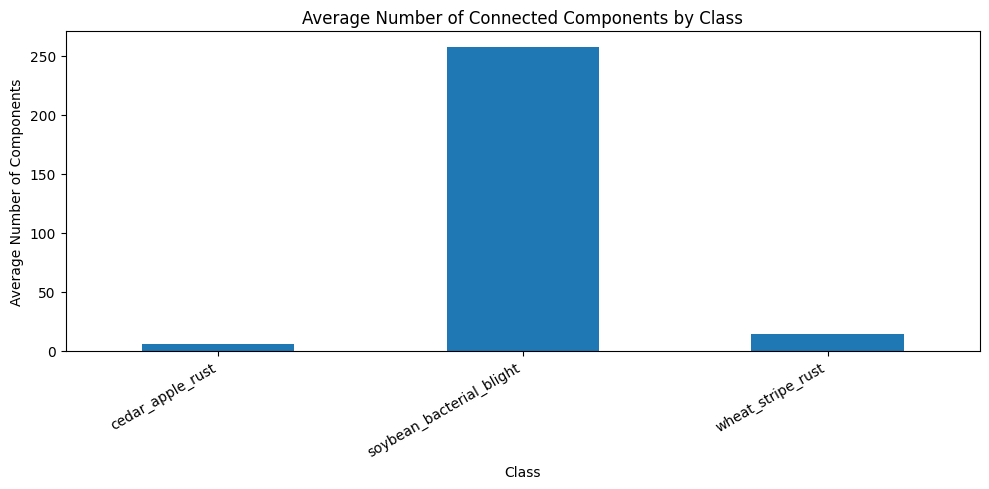

In [ ]:
plt.figure(figsize=(10, 5))

class_summary["num_components"].plot(
    kind="bar",
    title="Average Number of Connected Components by Class"
)

plt.xlabel("Class")
plt.ylabel("Average Number of Components")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Average Largest Component Area by Class

This bar chart compares the average area of the largest connected component across the three classes.

It provides a comparison of the largest detected regions in the binary masks.

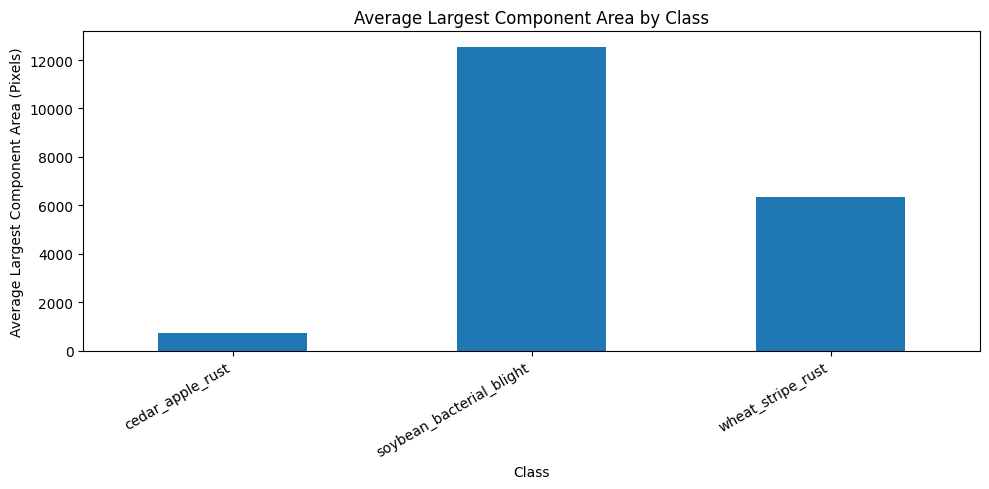

In [ ]:
plt.figure(figsize=(10, 5))

class_summary["largest_area"].plot(
    kind="bar",
    title="Average Largest Component Area by Class"
)

plt.xlabel("Class")
plt.ylabel("Average Largest Component Area (Pixels)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Morphological Operations

Morphological operations are applied to binary masks to study changes in their shapes and structures.

This section applies Opening and Closing operations to a selected binary mask using a 3×3 structuring element.

- Opening: Erosion followed by Dilation.
- Closing: Dilation followed by Erosion.

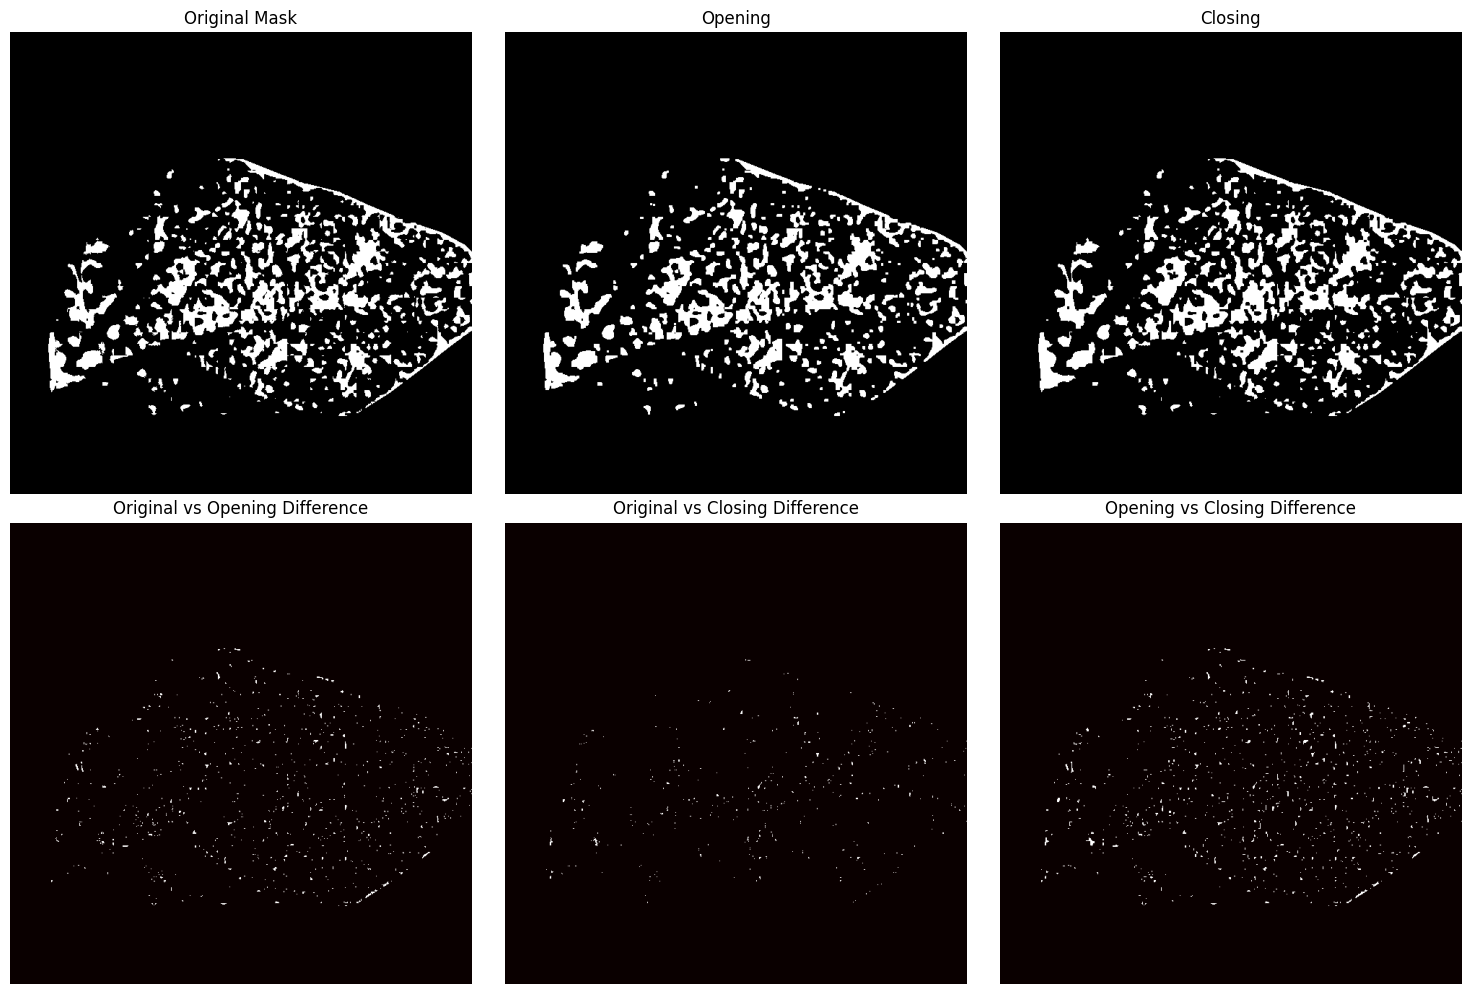

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(binary_mask, cmap="gray")
axes[0, 0].set_title("Original Mask")

axes[0, 1].imshow(opening, cmap="gray")
axes[0, 1].set_title("Opening")

axes[0, 2].imshow(closing, cmap="gray")
axes[0, 2].set_title("Closing")

axes[1, 0].imshow(
    cv2.absdiff(binary_mask, opening),
    cmap="hot"
)
axes[1, 0].set_title("Original vs Opening Difference")

axes[1, 1].imshow(
    cv2.absdiff(binary_mask, closing),
    cmap="hot"
)
axes[1, 1].set_title("Original vs Closing Difference")

axes[1, 2].imshow(
    np.logical_xor(opening, closing),
    cmap="hot"
)
axes[1, 2].set_title("Opening vs Closing Difference")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print("Original pixels:", binary_mask.sum())
print("Opening pixels:", opening.sum())
print("Closing pixels:", closing.sum())

print("Opening changed pixels:",
      np.sum(binary_mask != opening))

print("Closing changed pixels:",
      np.sum(binary_mask != closing))

Original pixels: 41457
Opening pixels: 39251
Closing pixels: 42275
Opening changed pixels: 2206
Closing changed pixels: 818


### Morphological Results Analysis

This section measures the binary mask before and after applying Opening and Closing.

The measurements include the number of connected components, total foreground pixels, largest component area, and smallest component area.

In [ ]:
def analyze_mask(binary_mask):

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8
    )

    areas = stats[1:, cv2.CC_STAT_AREA]

    return {
        "Components": len(areas),
        "Total foreground pixels": int(binary_mask.sum()),
        "Largest area": int(areas.max()) if len(areas) else 0,
        "Smallest area": int(areas.min()) if len(areas) else 0
    }


print("Original:", analyze_mask(binary_mask))
print("Opening:", analyze_mask(opening))
print("Closing:", analyze_mask(closing))

Original: {'Components': 288, 'Total foreground pixels': 41457, 'Largest area': 3238, 'Smallest area': 1}
Opening: {'Components': 241, 'Total foreground pixels': 39251, 'Largest area': 2272, 'Smallest area': 9}
Closing: {'Components': 256, 'Total foreground pixels': 42275, 'Largest area': 3293, 'Smallest area': 1}


### Morphological Mask Similarity Using IoU

Intersection over Union (IoU) measures the overlap between two binary masks.

In this experiment, IoU is used to compare the original binary mask with the masks produced by Opening and Closing.

This is a similarity measurement between processed and original masks, not a ground-truth segmentation accuracy score.

In [ ]:
def calculate_iou(mask1, mask2):

    intersection = np.logical_and(mask1, mask2).sum()

    union = np.logical_or(mask1, mask2).sum()

    return intersection / union if union > 0 else 1.0

In [ ]:
kernel_sizes = [3, 5, 7]

for size in kernel_sizes:

    kernel = np.ones((size, size), np.uint8)

    opened = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    closed = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    print(f"\nKernel Size: {size}x{size}")

    print(
        "Opening IoU:",
        calculate_iou(binary_mask, opened)
    )

    print(
        "Closing IoU:",
        calculate_iou(binary_mask, closed)
    )


Kernel Size: 3x3
Opening IoU: 0.9467882384157078
Closing IoU: 0.9806505026611473

Kernel Size: 5x5
Opening IoU: 0.7856815495573727
Closing IoU: 0.9241829773953364

Kernel Size: 7x7
Opening IoU: 0.5266661842390911
Closing IoU: 0.8175149375875057


### Visual Comparison of Morphological Kernel Sizes

This section visually compares the effects of different structuring element sizes on the binary mask.

Opening and Closing are applied using 3×3, 5×5, and 7×7 kernels to observe how kernel size affects the mask structure.

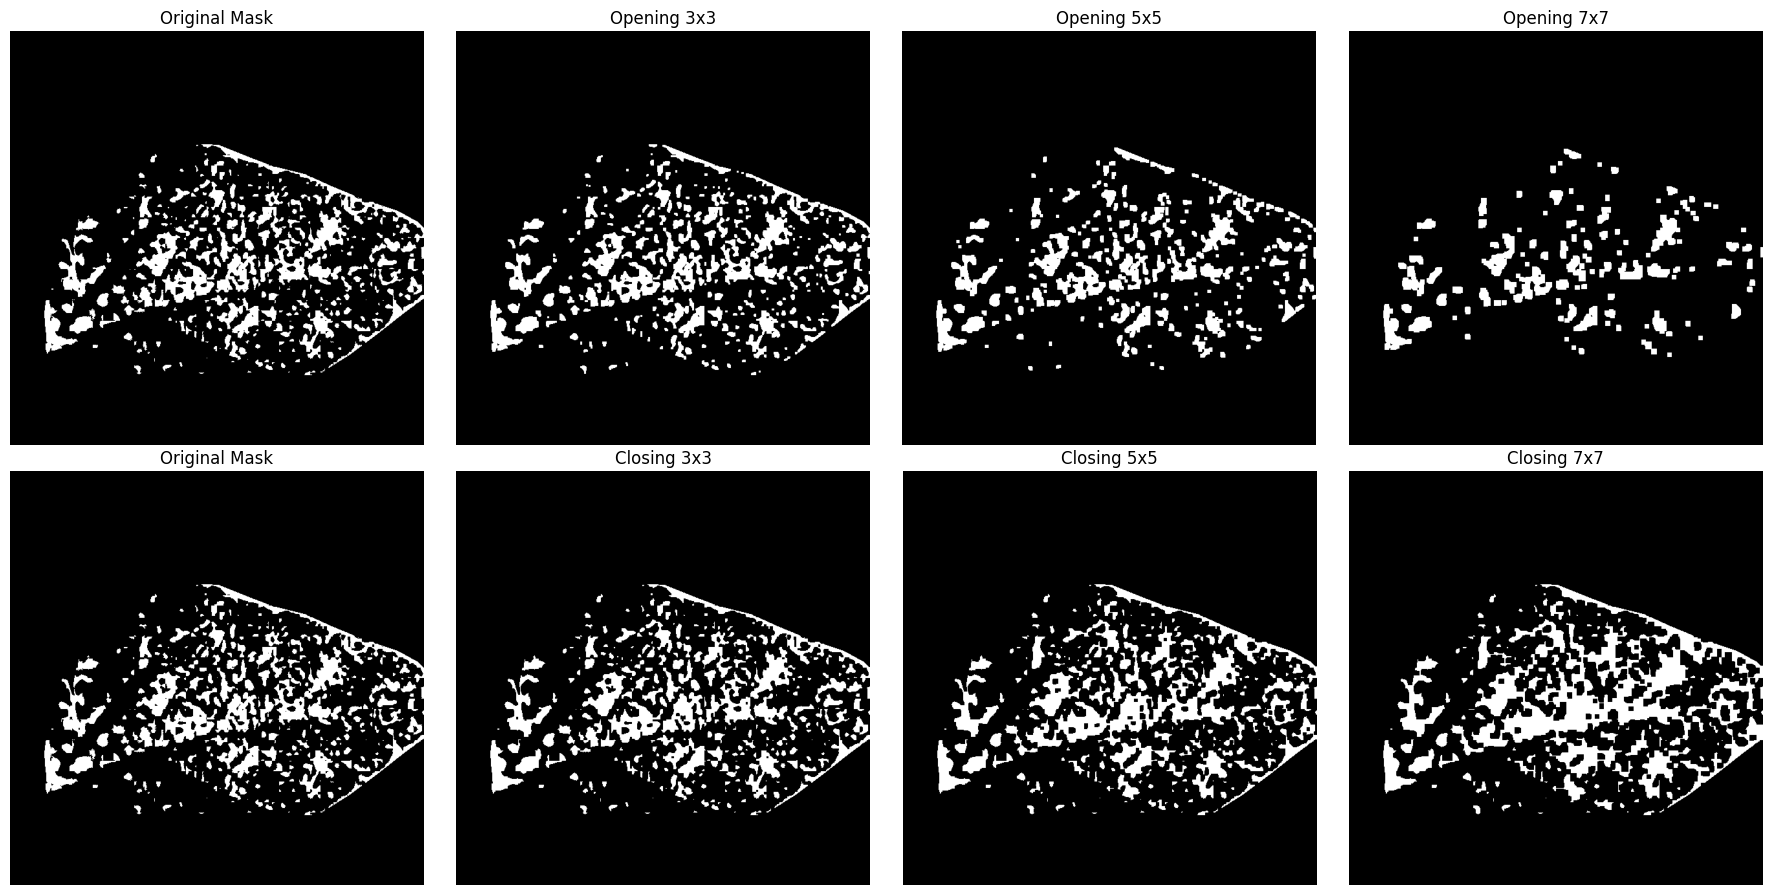

In [ ]:
kernel_sizes = [3, 5, 7]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes[0, 0].imshow(binary_mask, cmap="gray")
axes[0, 0].set_title("Original Mask")

axes[1, 0].imshow(binary_mask, cmap="gray")
axes[1, 0].set_title("Original Mask")

for i, size in enumerate(kernel_sizes, start=1):

    kernel = np.ones((size, size), np.uint8)

    opened = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    closed = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    axes[0, i].imshow(opened, cmap="gray")
    axes[0, i].set_title(f"Opening {size}x{size}")

    axes[1, i].imshow(closed, cmap="gray")
    axes[1, i].set_title(f"Closing {size}x{size}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Morphological Operations Comparison

This section compares Opening and Closing using different kernel sizes.

IoU values are calculated against the original binary mask to measure how much each operation changes the mask.

In [59]:
row = df.iloc[0]

label_path = os.path.join(DATASET_DIR, row["label"])
mask = np.array(Image.open(label_path))

binary_mask = (mask == 255).astype(np.uint8)

kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

In [60]:
comparison_results = []

for size in [3, 5, 7]:

    kernel = np.ones((size, size), np.uint8)

    opened = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_OPEN,
        kernel
    )

    closed = cv2.morphologyEx(
        binary_mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    comparison_results.append({
        "Kernel Size": f"{size}x{size}",
        "Opening IoU": calculate_iou(binary_mask, opened),
        "Closing IoU": calculate_iou(binary_mask, closed)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Kernel Size,Opening IoU,Closing IoU
0,3x3,0.946788,0.980651
1,5x5,0.785682,0.924183
2,7x7,0.526666,0.817515


## Morphological Comparison Across the Dataset

This section evaluates the effects of Opening and Closing operations across all dataset samples.

Three structuring element sizes (3×3, 5×5, and 7×7) are tested.

For each sample, the following measurements are recorded:
- Original foreground pixel count.
- Processed foreground pixel count.
- Number of changed pixels.
- IoU similarity between the original and processed masks.

The results are grouped by disease class and dataset split to examine the effects of morphological operations across the dataset.

In [ ]:

morphology_results = []

kernel_sizes = [3, 5, 7]

for _, row in df.iterrows():

    label_path = os.path.join(DATASET_DIR, row["label"])
    mask = np.array(Image.open(label_path))

    # Convert the disease region (255) into a binary mask
    binary_mask = (mask == 255).astype(np.uint8)

    for size in kernel_sizes:

        kernel = np.ones((size, size), np.uint8)

        opening = cv2.morphologyEx(
            binary_mask,
            cv2.MORPH_OPEN,
            kernel
        )

        closing = cv2.morphologyEx(
            binary_mask,
            cv2.MORPH_CLOSE,
            kernel
        )

        for operation_name, processed_mask in [
            ("Opening", opening),
            ("Closing", closing)
        ]:

            intersection = np.logical_and(
                binary_mask, processed_mask
            ).sum()

            union = np.logical_or(
                binary_mask, processed_mask
            ).sum()

            iou = intersection / union if union > 0 else 1.0

            morphology_results.append({
                "name": row["name"],
                "class": row["class"],
                "split": row["split"],
                "operation": operation_name,
                "kernel_size": f"{size}x{size}",
                "original_pixels": int(binary_mask.sum()),
                "processed_pixels": int(processed_mask.sum()),
                "changed_pixels": int(
                    np.sum(binary_mask != processed_mask)
                ),
                "IoU": float(iou)
            })

morphology_results_df = pd.DataFrame(morphology_results)

print("Total samples:", len(df))
print("Total experiment records:", len(morphology_results_df))

display(morphology_results_df.head(10))


Total samples: 240
Total experiment records: 1440


,name,class,split,operation,kernel_size,original_pixels,processed_pixels,changed_pixels,IoU
0,Soybean_0090,soybean_bacterial_blight,train,Opening,3x3,41457,39251,2206,0.946788
1,Soybean_0090,soybean_bacterial_blight,train,Closing,3x3,41457,42275,818,0.980651
2,Soybean_0090,soybean_bacterial_blight,train,Opening,5x5,41457,32572,8885,0.785682
3,Soybean_0090,soybean_bacterial_blight,train,Closing,5x5,41457,44858,3401,0.924183
4,Soybean_0090,soybean_bacterial_blight,train,Opening,7x7,41457,21834,19623,0.526666
5,Soybean_0090,soybean_bacterial_blight,train,Closing,7x7,41457,50711,9254,0.817515
6,Wheat_C230514_0082,wheat_stripe_rust,train,Opening,3x3,1904,1894,10,0.994748
7,Wheat_C230514_0082,wheat_stripe_rust,train,Closing,3x3,1904,1912,8,0.995816
8,Wheat_C230514_0082,wheat_stripe_rust,train,Opening,5x5,1904,1760,144,0.924370
9,Wheat_C230514_0082,wheat_stripe_rust,train,Closing,5x5,1904,1926,22,0.988577


In [ ]:

morphology_summary = (
    morphology_results_df
    .groupby(["operation", "kernel_size"])
    [["original_pixels", "processed_pixels",
      "changed_pixels", "IoU"]]
    .mean()
    .reset_index()
)

display(morphology_summary.round(4))


,operation,kernel_size,original_pixels,processed_pixels,changed_pixels,IoU
0,Closing,3x3,14984.7333,15291.6167,306.8833,0.9865
1,Closing,5x5,14984.7333,16195.5417,1210.8083,0.9532
2,Closing,7x7,14984.7333,17750.8333,2766.1000,0.9068
3,Opening,3x3,14984.7333,14300.6042,684.1292,0.9712
4,Opening,5x5,14984.7333,12574.1000,2410.6333,0.8846
5,Opening,7x7,14984.7333,10185.5083,4799.2250,0.7246


In [ ]:

class_morphology_summary = (
    morphology_results_df
    .groupby(["class", "operation", "kernel_size"])
    [["changed_pixels", "IoU"]]
    .mean()
    .reset_index()
)

display(class_morphology_summary.round(4))


,class,operation,kernel_size,changed_pixels,IoU
0,cedar_apple_rust,Closing,3x3,0.5250,0.9997
1,cedar_apple_rust,Closing,5x5,3.0000,0.9985
2,cedar_apple_rust,Closing,7x7,7.4250,0.9962
3,cedar_apple_rust,Opening,3x3,14.2500,0.9899
4,cedar_apple_rust,Opening,5x5,55.6375,0.9611
5,cedar_apple_rust,Opening,7x7,155.2375,0.8872
6,soybean_bacterial_blight,Closing,3x3,715.0125,0.9798
7,soybean_bacterial_blight,Closing,5x5,3016.1125,0.9188
8,soybean_bacterial_blight,Closing,7x7,7193.2250,0.8241
9,soybean_bacterial_blight,Opening,3x3,1975.7375,0.9321


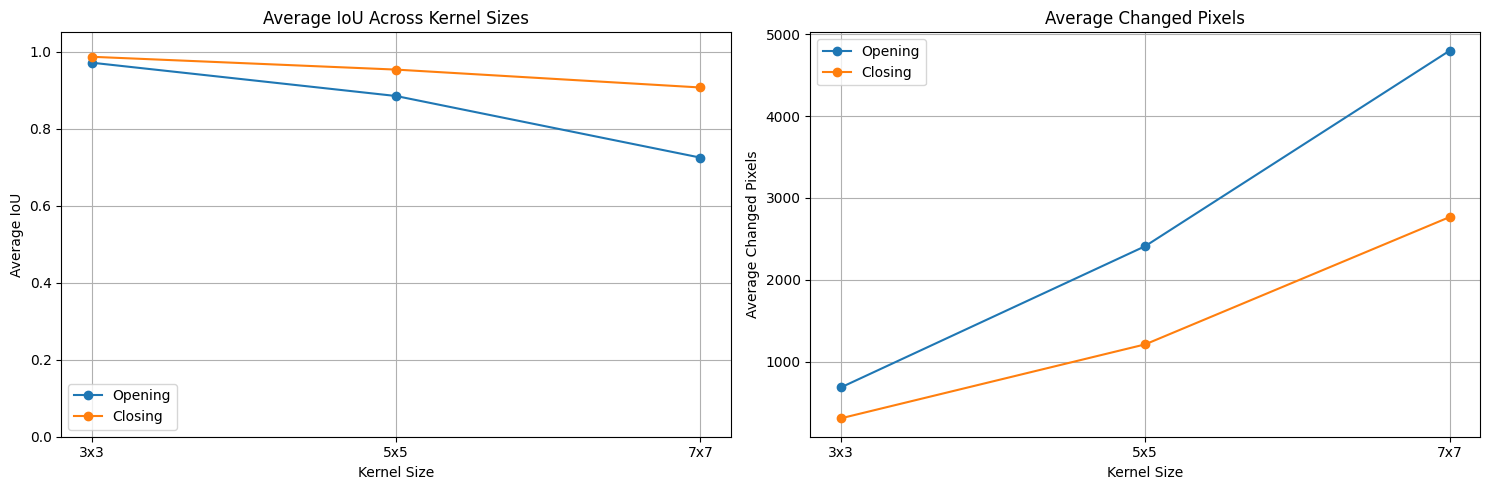

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for operation in ["Opening", "Closing"]:

    data = morphology_summary[
        morphology_summary["operation"] == operation
    ]

    axes[0].plot(
        data["kernel_size"],
        data["IoU"],
        marker="o",
        label=operation
    )

axes[0].set_title("Average IoU Across Kernel Sizes")
axes[0].set_xlabel("Kernel Size")
axes[0].set_ylabel("Average IoU")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(True)

for operation in ["Opening", "Closing"]:

    data = morphology_summary[
        morphology_summary["operation"] == operation
    ]

    axes[1].plot(
        data["kernel_size"],
        data["changed_pixels"],
        marker="o",
        label=operation
    )

axes[1].set_title("Average Changed Pixels")
axes[1].set_xlabel("Kernel Size")
axes[1].set_ylabel("Average Changed Pixels")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### Morphological Comparison – Analysis

The morphological operations were evaluated across all dataset samples using three kernel sizes.

The comparison examines how Opening and Closing affect the foreground pixel count and mask similarity.

The average IoU measures the similarity between each processed mask and its original binary mask.

The average number of changed pixels measures the extent of modification introduced by each operation.

Results are also grouped by disease class to investigate whether the morphological effects differ between classes.

**Note:** These measurements describe morphological changes and do not represent segmentation accuracy.

### Morphological Comparison – Results and Discussion

Morphological Opening and Closing operations were evaluated on all 240 dataset samples using three kernel sizes: 3×3, 5×5, and 7×7, producing 1,440 experiment records.

The results show that increasing the kernel size generally increases the number of modified pixels and decreases the IoU similarity with the original masks.

Closing achieved higher average IoU values than Opening across all tested kernel sizes. The highest similarity was obtained using a 3×3 kernel, with an average IoU of 0.9865 for Closing and 0.9712 for Opening.

The impact of morphological operations also varied across disease classes. Cedar Apple Rust masks were generally less affected, while Soybean Bacterial Blight masks showed greater changes, particularly with larger kernels.

Overall, the 3×3 kernel introduced the smallest changes to the original masks. Larger kernels produced more noticeable modifications and may remove or alter important regions.

**Note:** The reported IoU values measure similarity between the original masks and their morphologically processed versions. They do not represent segmentation model accuracy.

## Final Results and Conclusion

This project investigated the dataset masks and evaluated the effects of morphological operations across 240 samples.

The main findings are:

1. **Dataset Validation:** The dataset contains 240 samples divided into training, validation, and testing sets.
2. **Mask Analysis:** The label masks were examined to inspect their pixel values, dimensions, and consistency.
3. **Connected Components:** Connected-component analysis was performed to investigate the structure and distribution of foreground regions.
4. **Morphological Comparison:** Opening and Closing were tested using 3×3, 5×5, and 7×7 kernels across all 240 samples.
5. **Morphological Findings:** Smaller kernels generally preserved the original masks better, while larger kernels caused more substantial changes. The effects varied across disease classes.

### Conclusion

The analysis demonstrates that morphological operations can significantly affect segmentation masks, and their impact depends on both the kernel size and the disease class.

The 3×3 kernel generally preserved the original mask structure more effectively than larger kernels.

Segmentation performance evaluation using IoU, Dice Score, Precision, and Recall remains pending until the model's predicted masks are available. Therefore, no segmentation accuracy conclusions are reported at this stage.